# Two questions about graph-based retrieval in the RAG pipeline

1. **SQ1. Does HNSW cut single-query latency compared with the pipeline's exact retriever at matched recall, and what does it cost?** How large the speed-up is, where it comes from, and what it costs in memory, build time and answer quality.
2. **SQ2. Does reordering the graph to improve memory locality cut latency further?** How large and how reliable the gain is, which locality property predicts it, which hardware mechanism produces it, and what it costs.

Each section gives the evidence first and ends with **the answer as the evidence supports it**: the claim, the evidence, the alternatives ruled out, and the limits. The last section ties the two answers together.

**Data.** The course corpus: N = 24,000 documents, embedded as 384-dimensional float32 vectors (1536 B each). Queries are the course's 475 ASR-transcript queries (350 practice + 125 dev); answer quality uses the course qrels for the 125 dev queries.

**Machine.** Every measurement below (search latency, hardware counters, graph build, reorder time) was taken on one machine, named by its CPU. The single exception is the end-to-end pipeline share in §1e: the full pipeline needs a GPU, so that one figure comes from a Xeon Silver 4114 Slurm node.

| | Core Ultra 5 235U (12 MiB L3) |
|---|---|
| Cores | 2 P + 8 E + 2 LP-E (14 threads) |
| L1d / L2 / L3 | 48 KiB / 2 MiB per P-core / 12 MiB shared |
| Measurements ran on | one P-core (cpu 2), pinned with `taskset`; performance governor, turbo off, on AC |
| Pages | THP = `madvise` |
| Hardware counters | `perf` (user-space events) |
| SIMD / BLAS | `FAISS_SIMD_LEVEL=AVX2`, `OPENBLAS_CORETYPE=Haswell`, single-threaded |
| Software | FAISS 1.15.1, numpy 2.4.6, Python 3.12 (`env.txt` in every run directory) |

The HNSW working set (vectors + level-0 links, ≈38 MiB) is about 3× the L3.

**Machine-independent inputs:** recall, the qrels metrics, bytes per vector, and the offline graph statistics (`offline/locality.csv`).

**Conventions**
- **gain** = 1 − p50(ordering) ÷ p50(original order), on the same saved graph at the same efSearch, so at the same recall.
- **ndis** = distance computations per query (FAISS's counter; identical for every ordering).
- **ws** = working set = vectors + level-0 links.

**Parameter choices and why**

The questions compare search methods and memory layouts on one graph at matched recall; neither is "the fastest HNSW configuration". So every parameter is fixed in advance at a published default, rather than tuned, and every number reported is measured at a stated setting on all 475 queries. Tuning would add a selection step that could overfit the small course query set, and every course query is also used for evaluation.

- **Graph: M = 16, efConstruction = 200.** These are hnswlib's defaults (`init_index`), from the reference implementation by the HNSW authors, and a common starting configuration in ANN benchmarks. FAISS has no default for M (it must be passed to `IndexHNSWFlat`), and its default efConstruction of 40 is below common practice, so it offers no complete default to adopt. The cost of fixing the graph is that SQ1 and SQ2 are measured on this one configuration; §1f checks how much SQ1's answer depends on it by repeating the comparison on six configurations.
- **efSearch: swept, not fixed.** efSearch is a query-time setting that trades recall for cost, so, following ANN-Benchmarks practice (Aumüller et al.), §1 reports the whole sweep (ef = 16–512) with recall and latency at each point instead of choosing one value.
- **Operating points within the sweep.** Two points are carried into later sections:
  - ef = 32, the smallest ef in the sweep reaching recall@10 ≥ 0.95 on the 350 practice queries (0.965). Choosing it on practice queries keeps the 125 dev queries used for answer quality out of the choice.
  - ef = 64, the smallest ef in the sweep reaching recall@10 ≥ 0.99 on the same practice queries (0.991). It shows how the SQ1 and SQ2 results change as the search does more work.
  - Both are fixed by one rule stated in advance (smallest ef reaching the target), applied once by `retune.py` before the SQ2 measurements; no other queries were used.
- **Gorder window: w = 10.** Gorder's reference implementation defaults to w = 5. Our measurements were taken at w = 10, set before this analysis. §2f shows the choice does not matter: w = 3, 5 and 10 give the same gain within round-to-round noise, so SQ2's answer does not depend on it.

## 0. Config, loader and shared frames

In [1]:
from pathlib import Path
import json, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

HERE = Path.cwd()  # run the notebook from rag/results/ann-exp-data/
DATA_ROOTS = [HERE / "laptop" / "ann"]   # every measurement except the pipeline share
PIPELINE_ROOT = HERE / "ann"             # end-to-end pipeline share only (needs a GPU: Xeon Slurm node)
CLUSTER_HOST_PREFIXES = ("damnii",)      # hosts of the Xeon node
SAVE_FIGS = False                                       # True -> write PNGs to HERE/"figs"
FIG_DIR = HERE / "figs"

ROOTS = [r for r in DATA_ROOTS if r.is_dir()]
print("data roots:", *[str(r) for r in ROOTS], sep="\n  ")

SETTINGS = {}
for r in ROOTS:
    if (r / "settings.json").exists():
        SETTINGS[str(r)] = json.loads((r / "settings.json").read_text())
settings = next(iter(SETTINGS.values()), {})   # fixed graph configuration
CORPUS = "24k"
settings = {CORPUS: settings[CORPUS]}
OPS = [settings[CORPUS]["ef95"], settings[CORPUS]["ef99"]]   # operating points: recall >= 0.95 / >= 0.99 on practice queries
display(pd.DataFrame(settings).T)

pd.set_option("display.width", 200, "display.max_columns", 40, "display.float_format", "{:.4g}".format)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
ORDER_COLORS = {"identity": "#7f7f7f", "random": "#ff7f0e", "bfs": "#1f77b4", "gorder": "#2ca02c",
                "exact_dense": "black", "faiss_exact": "#9467bd"}
ULTRA = "Core Ultra 5 235U (12 MiB L3)"
XEON = "Xeon Silver 4114 (13.75 MiB L3/socket)"
MACHINES = [ULTRA]                            # every search/counter/build/reorder measurement
MACHINE_COLORS = {ULTRA: "#d62728", XEON: "#1f77b4"}
tick = lambda m: m.replace(" (", "\n(")      # two-line axis label

def savefig(fig, name):
    if SAVE_FIGS:
        FIG_DIR.mkdir(exist_ok=True)
        fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

data roots:
  /home/jetsykes/code/edin-mls-26-autumn/.claude/worktrees/laptop-rerun/rag/results/ann-exp-data/laptop/ann


,M,efc,ef95,ef99,gorder_w
24k,16,200,32,64,10


In [2]:
RUN_RE = re.compile(r"^(?P<host>.+)-(?P<ts>\d{8}T\d{6})$")

def machine_of(host):
    return XEON if str(host).startswith(CLUSTER_HOST_PREFIXES) else ULTRA

def run_dirs(step, roots=None):
    """All <root>/<step>/<host>-<ts>/ dirs (failed-* steps and report/ are never matched)."""
    return sorted(d for root in (roots or ROOTS) for d in (root / step).glob("*") if d.is_dir())

def load_step(step, pattern="rows*.csv", roots=None):
    frames = []
    for d in run_dirs(step, roots):
        m = RUN_RE.match(d.name)
        for f in sorted(d.glob(pattern)):
            df = pd.read_csv(f)
            df["step"], df["run"], df["file"], df["root"] = step, d.name, f.stem, d.parent.parent.name
            df["run_ts"] = pd.to_datetime(m["ts"]) if m else pd.NaT
            df["run_host"] = m["host"] if m else d.name
            frames.append(df)
    if not frames:
        return pd.DataFrame()
    df = pd.concat(frames, ignore_index=True)
    host = df["host"] if "host" in df else df["run_host"]
    df["host_short"] = host.astype(str).str.split(".").str[0]
    df["machine"] = df["host_short"].map(machine_of)
    if "order" in df:
        df["order_family"] = df["order"].astype(str).str.split(":").str[0]
    if "ef" in df:
        df["ef"] = pd.to_numeric(df["ef"], errors="coerce")  # float: exact rows have no ef
    if "corpus" in df:
        df = df[df["corpus"] == CORPUS]
    return df

def latest_per_cell(df, keys, label=""):
    """Keep only rows from the newest run within each cell (one cell = one value of `keys`)."""
    if df.empty:
        return df
    keys = [k for k in keys if k in df]
    newest = df.groupby(keys, dropna=False)["run_ts"].transform("max")
    kept = df[df["run_ts"] == newest]
    dropped = len(df) - len(kept)
    src = kept.groupby("run").size().rename("rows kept")
    print(f"{label}: kept {len(kept)} rows, dropped {dropped} superseded rows; source runs:")
    print(src.to_string())
    return kept.copy()

def parse_env(run_dir):
    """Selected fields from a run's env.txt (key: value lines and KEY=VALUE tokens)."""
    p = Path(run_dir) / "env.txt"
    out = {"run": Path(run_dir).name, "step": Path(run_dir).parent.name}
    if not p.exists():
        return out
    for line in p.read_text().splitlines():
        if line.startswith("settings.json"):
            break
        if re.match(r"^(step|date|host|slurm|git): ", line):
            k, v = line.split(": ", 1); out[k] = v
        elif line.startswith("python "):
            out["python/faiss"] = line
        else:
            for tok in re.findall(r"(\w+)=(\S+)", line):
                out.setdefault(tok[0], tok[1])
    return out

def size_bytes(text):
    """lscpu '27.5 MiB (2 instances)' -> bytes per instance (same as exp.py)."""
    m = re.match(r"([\d.]+)\s*([KMG])i?B?(?:\s*\((\d+) instance)?", str(text or ""))
    if not m:
        return np.nan
    return float(m.group(1)) * {"K": 1 << 10, "M": 1 << 20, "G": 1 << 30}[m.group(2)] / int(m.group(3) or 1)

def working_set(df):
    """Raw vectors + level-0 links (exp.py's definition); exact search: vectors only."""
    links = np.where(df["index"] == "hnsw", 2 * df["M"].fillna(0) * 4, 0)
    return df["n"] * (df["d"] * 4 + links)

STEPS = ["graph", "1-setup", "3-stage1", "4-reorder", "reorder-time", "9-quality", "perf", "build", "retune"]

In [3]:
s1 = latest_per_cell(load_step("3-stage1"), ["machine", "corpus", "index", "M", "efc", "ef", "round"], "3-stage1")
s1 = s1[s1["mode"] == "time"]
s4 = latest_per_cell(load_step("4-reorder"), ["machine", "corpus", "ef", "order", "round"], "4-reorder")
s4 = s4[(s4["mode"] == "time") & s4["ef"].isin(OPS)]
perf = latest_per_cell(load_step("perf"), ["machine", "corpus", "index", "ef", "order", "round"], "perf")
perf = perf[(perf["mode"] == "perf") & (perf["ef"].isin(OPS) | perf["ef"].isna())]
pt = perf.groupby(["index", "ef", "order"], dropna=False)[
    ["cycles_per_q", "ipc", "LLC_loads_per_q", "LLC_load_misses_per_q", "L1_dcache_load_misses_per_q",
     "dTLB_load_misses_per_q", "ndis_per_q"]].median().reset_index()
loc = pd.read_csv(HERE / "offline" / "locality.csv")
loc = loc[loc["corpus"] == CORPUS]
L3 = {m: size_bytes(t) for m, t in s4.groupby("machine")["l3"].first().items()}
GORDER = f"gorder:{settings[CORPUS]['gorder_w']}"
print("Gorder ordering:", GORDER, "| L3 (MiB):", {k: v / 2**20 for k, v in L3.items()})
assert set(s1["machine"]) == set(s4["machine"]) == {ULTRA}, "only Core Ultra rows expected"
ws = working_set(s1[s1["index"] == "hnsw"].iloc[[0]]).iloc[0]
print(f"HNSW working set (vectors + level-0 links): {ws / 2**20:.1f} MiB = {ws / L3[ULTRA]:.1f}x the L3")

3-stage1: kept 24 rows, dropped 0 superseded rows; source runs:
run
jetsykes-hp-ubuntu-20261114T170314    24
4-reorder: kept 120 rows, dropped 40 superseded rows; source runs:
run
jetsykes-hp-ubuntu-20261114T170314    40
jetsykes-hp-ubuntu-20261117T210903    80
perf: kept 78 rows, dropped 27 superseded rows; source runs:
run
jetsykes-hp-ubuntu-20261114T170314    27
jetsykes-hp-ubuntu-20261117T211147    51
Gorder ordering: gorder:10 | L3 (MiB): {'Core Ultra 5 235U (12 MiB L3)': 12.0}
HNSW working set (vectors + level-0 links): 38.1 MiB = 3.2x the L3


### 0b. Inputs: one graph, one ground truth, checked

Every timing step loads one saved HNSW graph, one exact top-100 ground truth and one cached permutation per ordering. All of them were regenerated on the Core Ultra by `extensions/scripts/laptop_rerun.py` and compared with the files the timing steps loaded:
- **Graph:** rebuilt from scratch on one pinned thread and compared by link hash and by whole-file hash.
- **Ground truth:** exact top-100 recomputed with numpy (`exp.py prep`), compared array for array; the same step checks that FAISS `IndexFlatIP` and numpy return the same exact neighbours.
- **Permutations:** recomputed while being timed (§2e) and compared by hash.

In [4]:
g = load_step("graph", "rows.csv")
display(Markdown(f"**Graph rebuilt on the {ULTRA}** (1 thread, cpu 2) against the file every timing step loaded"))
display(g[["M", "efc", "threads", "build_s", "links_sha1", "same_links", "file_sha1", "same_file"]])
pr = load_step("1-setup", "rows-vs-cached.csv")
display(Markdown(f"**Ground truth and query vectors regenerated on the {ULTRA}** against the files every timing step loaded"))
display(pr[["item", "nq", "identical", "rows_identical", "top10_sets_identical"]])
chk = json.loads((run_dirs("1-setup")[-1] / "check.json").read_text())
display(Markdown("**FAISS exact against numpy exact** (top-k agreement and largest rank-wise score difference)"))
display(pd.DataFrame(chk["exact_agreement"]).T[["nq", "top10_rows_same_set", "top100_rows_same_set",
                                                "max_abs_rankwise_score_diff", "verdict"]])

**Graph rebuilt on the Core Ultra 5 235U (12 MiB L3)** (1 thread, cpu 2) against the file every timing step loaded

,M,efc,threads,build_s,links_sha1,same_links,file_sha1,same_file
0,16,200,1,12.39,d092115bc6ac,True,1308437fad3c,True


**Ground truth and query vectors regenerated on the Core Ultra 5 235U (12 MiB L3)** against the files every timing step loaded

,item,nq,identical,rows_identical,top10_sets_identical
0,gt-course-k100.npy,475,False,0.9811,1
1,gt-fiqa_extra-k100.npy,6173,False,0.9866,1
2,queries/course.npy,NaN,True,NaN,NaN
3,queries/course_ids.json,NaN,True,NaN,NaN


**FAISS exact against numpy exact** (top-k agreement and largest rank-wise score difference)

,nq,top10_rows_same_set,top100_rows_same_set,max_abs_rankwise_score_diff,verdict
24k/course,475,1,1,5.96e-07,agree up to float rounding
24k/fiqa_extra,6173,1,0.9997,5.96e-07,agree up to float rounding


## 1. SQ1: Does HNSW cut single-query latency against the pipeline's exact retriever at matched recall, and at what cost?

**Baseline.** The baseline is `ExactDenseRetriever`, the pipeline's own exact retriever. It is a direct numpy implementation (matrix-vector product, then `argpartition`). FAISS `IndexFlatIP` is shown beside it for context, to check that the comparison isn't just against a weak implementation (§1c).

**Hypothesis.** At matched recall, HNSW is much faster because it evaluates far fewer vectors. But each vector it evaluates should cost more than one read by exact search:
- Exact search streams all N vectors in order, which the hardware prefetchers handle well.
- HNSW jumps to a vector at an unrelated address on every distance computation.

So the speed-up should be smaller than the reduction in work, and the gap should show up as memory misses.

**Scope: one query at a time, one thread.** This is how the pipeline uses the retriever. `RAGPipeline.answer_audio` (`src/rag.py`) transcribes one audio question, encodes it, and calls `retriever.retrieve` with that single query vector. The driver scripts loop over questions one by one, and neither retriever accepts several queries at once. So the claim is about single-query latency. Batched search, where many queries are passed in one call, is shown after the main curves only to mark where HNSW's advantage ends.

**Procedure.** Each cell (index × ef) runs in its own process pinned to cpu 2, so start-up and loading are never timed. One untimed warm-up pass over all 475 queries also gives recall; then 5 timed passes give 2,375 per-query latencies (`perf_counter_ns` around each call), from which p50 and p99 are taken. Cells are interleaved in a shuffled order over 3 rounds; the table reports the median over rounds.

In [5]:
GK = ["machine", "index", "ef"]
curve = (s1.groupby(GK, dropna=False)
           .agg(recall=("recall_at_k", "median"), p50_us=("p50_us", "median"), p99_us=("p99_us", "median"),
                ndis=("ndis_per_q", "median"), index_bytes=("index_bytes", "first"), n=("n", "first"),
                build_s=("build_s", "median"))
           .reset_index())
N = int(curve["n"].iloc[0])
exd = curve[curve["index"] == "exact_dense"].set_index("machine")
ex = curve[curve["index"] == "faiss_exact"].set_index("machine")
h = curve[curve["index"] == "hnsw"].copy()
h = h.join(exd[["p50_us"]].add_prefix("dense_"), on="machine").join(ex[["p50_us"]].add_prefix("faiss_"), on="machine")
h["speedup_vs_dense"] = h["dense_p50_us"] / h["p50_us"]
h["speedup_vs_faiss"] = h["faiss_p50_us"] / h["p50_us"]
cols = ["machine", "ef", "recall", "p50_us", "p99_us", "dense_p50_us", "speedup_vs_dense", "faiss_p50_us", "speedup_vs_faiss"]
display(Markdown(f"**HNSW single-query p50 against the `ExactDenseRetriever` baseline (FAISS exact for context)**, N = {N:,}; "
                 f"ef = {OPS[0]} (recall ≥ 0.95 operating point) and ef = {OPS[1]} (recall ≥ 0.99 operating point)"))
display(h[h["ef"].isin(OPS)][cols].sort_values(["machine", "ef"]).reset_index(drop=True).round(3))

**HNSW single-query p50 against the `ExactDenseRetriever` baseline (FAISS exact for context)**, N = 24,000; ef = 32 (recall ≥ 0.95 operating point) and ef = 64 (recall ≥ 0.99 operating point)

,machine,ef,recall,p50_us,p99_us,dense_p50_us,speedup_vs_dense,faiss_p50_us,speedup_vs_faiss
0,Core Ultra 5 235U (12 MiB L3),32,0.964,112.4,153.7,2167,19.28,1991,17.72
1,Core Ultra 5 235U (12 MiB L3),64,0.989,196.6,259.7,2167,11.02,1991,10.13


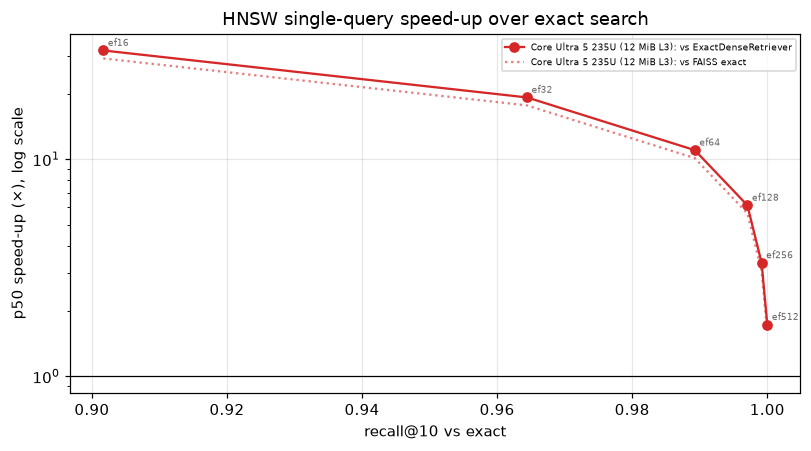

In [6]:
fig, ax = plt.subplots(figsize=(7.5, 4.2))
for m in MACHINES:
    g = h[h["machine"] == m].sort_values("recall")
    ax.plot(g["recall"], g["speedup_vs_dense"], marker="o", c=MACHINE_COLORS[m], label=f"{m}: vs ExactDenseRetriever")
    ax.plot(g["recall"], g["speedup_vs_faiss"], ls=":", c=MACHINE_COLORS[m], alpha=0.6, label=f"{m}: vs FAISS exact")
    if m == ULTRA:
        for _, r in g.iterrows():
            ax.annotate(f"ef{r['ef']:g}", (r["recall"], r["speedup_vs_dense"]), fontsize=6, alpha=0.6,
                        xytext=(3, 3), textcoords="offset points")
ax.axhline(1, c="k", lw=0.8)
ax.set(yscale="log", title="HNSW single-query speed-up over exact search", xlabel="recall@10 vs exact",
       ylabel="p50 speed-up (×), log scale")
ax.legend(fontsize=6)
fig.tight_layout(); savefig(fig, "orig_c1_speedup")

The same trade-off in the more common form: absolute single-query p50 latency against recall, with the exact baselines as horizontal lines. The speed-up is the vertical gap between an HNSW curve and its machine's baseline.

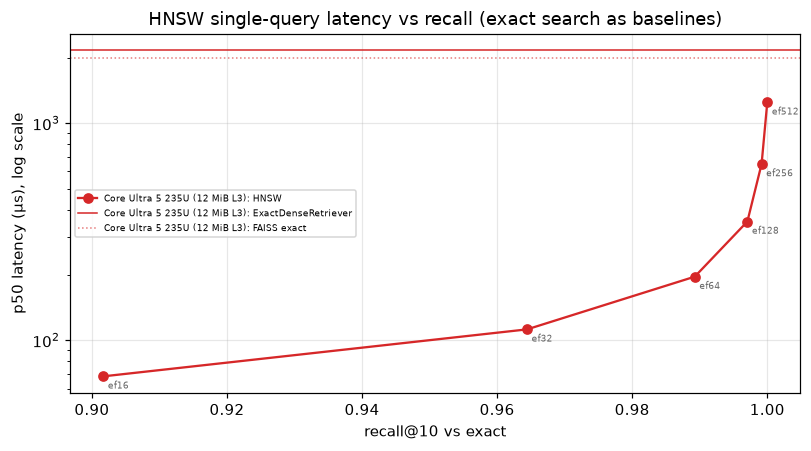

In [7]:
fig, ax = plt.subplots(figsize=(7.5, 4.2))
for m in MACHINES:
    c = MACHINE_COLORS[m]
    g = h[h["machine"] == m].sort_values("recall")
    ax.plot(g["recall"], g["p50_us"], marker="o", c=c, label=f"{m}: HNSW")
    ax.axhline(exd.loc[m, "p50_us"], c=c, lw=1, label=f"{m}: ExactDenseRetriever")
    ax.axhline(ex.loc[m, "p50_us"], c=c, lw=1, ls=":", alpha=0.6, label=f"{m}: FAISS exact")
    if m == ULTRA:
        for _, r in g.iterrows():
            ax.annotate(f"ef{r['ef']:g}", (r["recall"], r["p50_us"]), fontsize=6, alpha=0.6,
                        xytext=(3, -8), textcoords="offset points")
ax.set(yscale="log", title="HNSW single-query latency vs recall (exact search as baselines)",
       xlabel="recall@10 vs exact", ylabel="p50 latency (µs), log scale")
ax.legend(fontsize=6)
fig.tight_layout(); savefig(fig, "orig_c1_latency")

**Batched: a limit, not the pipeline's case.** The pipeline retrieves one query at a time, so this figure only shows where HNSW's advantage ends. Here every query is passed to FAISS in a single call, still on one thread. That call is timed once, so there is no per-query latency distribution and no p50. The y-axis is the amortised time per query, 1 / batch QPS (median over rounds). `ExactDenseRetriever` has no batched call, so FAISS exact is the only baseline here. Batched exact search becomes a matrix multiply that reuses each vector for every query in the batch. A graph walk cannot share work between queries in that way.

,machine,ef,recall,us_per_q,faiss_us_per_q,batched_speedup_vs_faiss,single_speedup_vs_faiss
0,Core Ultra 5 235U (12 MiB L3),16,0.902,61.07,360.7,5.906,29.16
1,Core Ultra 5 235U (12 MiB L3),32,0.964,107.3,360.7,3.362,17.72
2,Core Ultra 5 235U (12 MiB L3),64,0.989,185.1,360.7,1.948,10.13
3,Core Ultra 5 235U (12 MiB L3),128,0.997,338.9,360.7,1.064,5.641
4,Core Ultra 5 235U (12 MiB L3),256,0.999,645.1,360.7,0.559,3.066
5,Core Ultra 5 235U (12 MiB L3),512,1,1246,360.7,0.289,1.593


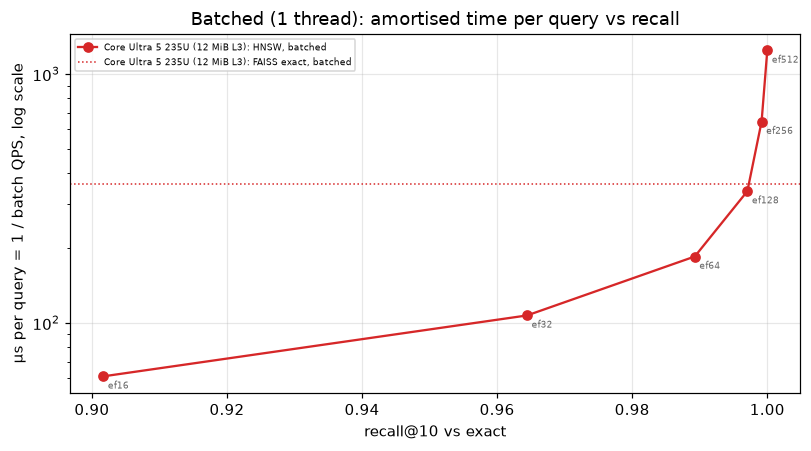

In [8]:
bq = (s1.groupby(GK, dropna=False)["batch_qps"].median().rename("batch_qps").reset_index()
        .merge(curve[GK + ["recall"]], on=GK))
bq["us_per_q"] = 1e6 / bq["batch_qps"]
bh = bq[bq["index"] == "hnsw"].copy()
bx = bq[bq["index"] == "faiss_exact"].set_index("machine")
bh = bh.join(bx[["us_per_q"]].add_prefix("faiss_"), on="machine")
bh["batched_speedup_vs_faiss"] = bh["faiss_us_per_q"] / bh["us_per_q"]
bh = bh.merge(h[["machine", "ef", "speedup_vs_faiss"]].rename(columns={"speedup_vs_faiss": "single_speedup_vs_faiss"}),
              on=["machine", "ef"])
display(bh[["machine", "ef", "recall", "us_per_q", "faiss_us_per_q", "batched_speedup_vs_faiss", "single_speedup_vs_faiss"]]
        .sort_values(["machine", "ef"]).reset_index(drop=True).round(3))

fig, ax = plt.subplots(figsize=(7.5, 4.2))
for m in MACHINES:
    c = MACHINE_COLORS[m]
    g = bh[bh["machine"] == m].sort_values("recall")
    ax.plot(g["recall"], g["us_per_q"], marker="o", c=c, label=f"{m}: HNSW, batched")
    ax.axhline(bx.loc[m, "us_per_q"], c=c, lw=1, ls=":", label=f"{m}: FAISS exact, batched")
    if m == ULTRA:
        for _, r in g.iterrows():
            ax.annotate(f"ef{r['ef']:g}", (r["recall"], r["us_per_q"]), fontsize=6, alpha=0.6,
                        xytext=(3, -8), textcoords="offset points")
ax.set(yscale="log", title="Batched (1 thread): amortised time per query vs recall",
       xlabel="recall@10 vs exact", ylabel="µs per query = 1 / batch QPS, log scale")
ax.legend(fontsize=6)
fig.tight_layout(); savefig(fig, "orig_c1_batched")

### 1b. Where the speed-up comes from: fewer vectors × cost per vector

The speed-up splits exactly into two factors:
- **Fewer vectors:** N ÷ ndis. Exact search reads all N vectors; HNSW evaluates ndis.
- **Dearer vectors:** HNSW's time per distance computation ÷ exact search's time per vector.

speed-up = fewer ÷ dearer. HNSW's time per vector includes everything else it does per step: reading links, the visited table and the candidate heap.

On the Core Ultra, `perf` gives the hardware cost per vector for both. A vector is 24 cache lines.

In [9]:
rows = []
for m in MACHINES:
    for ef in OPS:
        a = h[(h["machine"] == m) & (h["ef"] == ef)].iloc[0]
        r = dict(machine=m, ef=ef, vectors_exact=N, vectors_hnsw=a["ndis"], fewer_vectors=N / a["ndis"],
                 ns_per_vector_exact=1e3 * a["dense_p50_us"] / N, ns_per_vector_hnsw=1e3 * a["p50_us"] / a["ndis"])
        r["dearer_per_vector"] = r["ns_per_vector_hnsw"] / r["ns_per_vector_exact"]
        r["speedup = fewer / dearer"] = r["fewer_vectors"] / r["dearer_per_vector"]
        rows.append(r)
dec = pd.DataFrame(rows)
display(Markdown("**Speed-up = (vectors exact search reads ÷ vectors HNSW evaluates) ÷ (HNSW's time per vector ÷ exact's)**"))
display(dec.round(2))

pe = pt.set_index(["index", "ef", "order"])
rows = []
for name, key, per in [("ExactDenseRetriever", ("exact_dense", np.nan, np.nan), N),
                       (f"HNSW ef{OPS[0]}", ("hnsw", float(OPS[0]), "identity"), None), (f"HNSW ef{OPS[1]}", ("hnsw", float(OPS[1]), "identity"), None)]:
    p = pt[(pt["index"] == key[0]) & ((pt["ef"] == key[1]) if key[0] == "hnsw" else pt["ef"].isna())
           & ((pt["order"] == key[2]) if key[0] == "hnsw" else True)].iloc[0]
    v = per or p["ndis_per_q"]
    rows.append({"": name, "vectors per query": v, "cycles per vector": p["cycles_per_q"] / v,
                 "LLC misses per vector": p["LLC_load_misses_per_q"] / v, "LLC loads per vector": p["LLC_loads_per_q"] / v,
                 "dTLB misses per vector": p["dTLB_load_misses_per_q"] / v, "IPC": p["ipc"]})
display(Markdown(f"**Per-vector hardware cost on the {ULTRA}** (`perf`, warm cache; a vector is 24 cache lines)"))
display(pd.DataFrame(rows).set_index("").round(3))

**Speed-up = (vectors exact search reads ÷ vectors HNSW evaluates) ÷ (HNSW's time per vector ÷ exact's)**

,machine,ef,vectors_exact,vectors_hnsw,fewer_vectors,ns_per_vector_exact,ns_per_vector_hnsw,dearer_per_vector,speedup = fewer / dearer
0,Core Ultra 5 235U (12 MiB L3),32,24000,641.4,37.42,90.28,175.2,1.94,19.28
1,Core Ultra 5 235U (12 MiB L3),64,24000,1063,22.59,90.28,185,2.05,11.02


**Per-vector hardware cost on the Core Ultra 5 235U (12 MiB L3)** (`perf`, warm cache; a vector is 24 cache lines)

,vectors per query,cycles per vector,LLC misses per vector,LLC loads per vector,dTLB misses per vector,IPC
,,,,,,
ExactDenseRetriever,2.4e+04,184.5,2.653,3.691,0,0.843
HNSW ef32,641.4,351.4,6.836,10.25,0.926,0.755
HNSW ef64,1063,372.4,7.192,10.69,1,0.699


### 1c. Is the baseline a fair one? `ExactDenseRetriever` against FAISS exact

Both compute all N inner products and keep the top k, through different code paths:
- **`ExactDenseRetriever`:** OpenBLAS `sgemv`, then N-sized temporaries for `-scores` and `argpartition`. The timed region also includes Python input checks and query normalisation.
- **FAISS:** one SIMD inner product per vector, fed straight into a top-k heap.

If HNSW's advantage is algorithmic, the two exact implementations should be close. The speed-up should then be about the same against either one. *Effective bandwidth* = vector bytes ÷ p50.

In [10]:
bl_ = pd.DataFrame({"ExactDenseRetriever_p50_us": exd["p50_us"], "FAISS_exact_p50_us": ex["p50_us"]})
bl_["dense_over_faiss"] = bl_["ExactDenseRetriever_p50_us"] / bl_["FAISS_exact_p50_us"]
for k in ["ExactDenseRetriever", "FAISS_exact"]:
    bl_[f"{k}_GB_per_s"] = N * 1536 / (bl_[f"{k}_p50_us"] * 1e3)
display(bl_.round(3))

,ExactDenseRetriever_p50_us,FAISS_exact_p50_us,dense_over_faiss,ExactDenseRetriever_GB_per_s,FAISS_exact_GB_per_s
machine,,,,,
Core Ultra 5 235U (12 MiB L3),2167,1991,1.088,17.01,18.52


### 1d. What HNSW costs that exact search doesn't

- **Memory:** level-0 links plus upper levels, per vector.
- **A one-off graph build:** timed by `extensions/scripts/build_bench.py`.
  - Each build runs in a fresh process pinned with `taskset` (1 thread on cpu 2; 2 threads on the two P-cores, cpus 0 and 2), interleaved across 5 rounds, and is then discarded.
  - `all_same_as_cached` checks that each build reproduces, hash for hash, the saved graph every search step used (§0b): FAISS 1.15.1 builds it deterministically at these settings.
- **Payback:** the single-thread build time ÷ the per-query p50 saving at ef = 32. Both come from the same pinned core.

In [11]:
extra = (h["index_bytes"] / h["n"] - 384 * 4).iloc[0]
display(Markdown(f"**Memory exact search doesn't need:** {extra:.0f} B per vector of level-0 links and upper levels "
                 f"(+{100 * extra / 1536:.1f}% on the 1536 B vector; machine-independent)"))

bl = pd.concat([pd.read_csv(f).assign(run=f.parent.name) for f in sorted((HERE / "laptop" / "ann" / "build").glob("*/rows.csv"))],
               ignore_index=True)
bl = bl[(bl["run"] == bl["run"].max()) & (bl["corpus"] == CORPUS)]
bt = bl.groupby(["threads", "cpus"]).agg(
    builds=("build_s", "size"), build_s_median=("build_s", "median"), build_s_min=("build_s", "min"),
    build_s_max=("build_s", "max"), peak_rss_mb=("peak_rss_mb", "median"),
    distinct_graphs=("graph_sha1", "nunique"), all_same_as_cached=("same_as_cached", "all"))
bt["spread_%"] = 100 * (bt["build_s_max"] - bt["build_s_min"]) / bt["build_s_median"]
display(Markdown(f"**Graph build, timed on the {ULTRA}** (5 interleaved builds per row; cpus 0 and 2 are the two P-cores)"))
display(bt.round(3))
one = bt.xs(1, level="threads")["build_s_median"].iloc[0]
two = bt.xs(2, level="threads")["build_s_median"].iloc[0]
q32 = h[(h["machine"] == ULTRA) & (h["ef"] == 32)].iloc[0]
pay = pd.Series({"build_s_1t": one, "speedup_2t": one / two, "us_per_insert_1t": 1e6 * one / N,
                 "saving_per_query_us_vs_dense": q32["dense_p50_us"] - q32["p50_us"],
                 "payback_queries_vs_dense": one / ((q32["dense_p50_us"] - q32["p50_us"]) * 1e-6),
                 "payback_queries_vs_faiss": one / ((q32["faiss_p50_us"] - q32["p50_us"]) * 1e-6)})
display(Markdown("**Build and payback at ef = 32** (single-thread build ÷ single-query p50 saving)"))
display(pay.round(1).to_frame("value"))

**Memory exact search doesn't need:** 144 B per vector of level-0 links and upper levels (+9.4% on the 1536 B vector; machine-independent)

**Graph build, timed on the Core Ultra 5 235U (12 MiB L3)** (5 interleaved builds per row; cpus 0 and 2 are the two P-cores)

,,builds,build_s_median,build_s_min,build_s_max,peak_rss_mb,distinct_graphs,all_same_as_cached,spread_%
threads,cpus,,,,,,,,
1,2,5,12.21,12.2,12.32,154.9,1,True,1.061
2,"0,2",5,6.195,6.152,6.487,154.9,1,True,5.407


**Build and payback at ef = 32** (single-thread build ÷ single-query p50 saving)

,value
build_s_1t,12.2
speedup_2t,2
us_per_insert_1t,508.7
saving_per_query_us_vs_dense,2054
payback_queries_vs_dense,5943
payback_queries_vs_faiss,6499


### 1e. Context: answer quality and share of end-to-end time

- **Answer quality** uses the course qrels on the 125 dev queries, with the graph rebuilt on the Core Ultra (§0b). Δ is HNSW minus exact.
- **End-to-end share:** the full pipeline (ASR → retrieval → generation → TTS) needs a GPU, so it ran on a Xeon Silver 4114 Slurm node with a GPU. This is the only figure in the notebook not measured on the Core Ultra. Medians are used because that node is shared and unpinned, and rare outliers dominate the mean.

In [12]:
q = load_step("9-quality")
q = q[q["run_ts"] == q["run_ts"].max()].reset_index(drop=True)
mets = ["recall@10", "mrr@10", "ndcg@10"]
exq = q[q["method"] == "exact"][mets].iloc[0]
for m_ in mets:
    q[f"Δ{m_}"] = q[m_] - exq[m_]
display(Markdown("**Answer quality against the course qrels** (machine-independent)"))
display(q[q["method"] != "exact"][["method", "ef", "recall_vs_exact@10"] + [f"Δ{m_}" for m_ in mets]].round(4))
pl = load_step("11-pipeline", "rows.csv", roots=[PIPELINE_ROOT])   # the one Xeon measurement
display(Markdown(f"**Retrieval's share of an end-to-end RAG query** (medians; GPU pipeline on the {XEON} node)"))
display(pl.groupby("retriever")[["retrieval_ms", "end_to_end_ms", "retrieval_share"]].median().round(4))

**Answer quality against the course qrels** (machine-independent)

,method,ef,recall_vs_exact@10,Δrecall@10,Δmrr@10,Δndcg@10
1,hnsw,32,0.9632,-0.0096,-0.0015,-0.0022
2,hnsw,64,0.9856,-0.0027,0.0007,0.0001


**Retrieval's share of an end-to-end RAG query** (medians; GPU pipeline on the Xeon Silver 4114 (13.75 MiB L3/socket) node)

,retrieval_ms,end_to_end_ms,retrieval_share
retriever,,,
exact_dense,4.811,9617,0.0005
hnsw,0.5637,9978,0.0001


### 1f. Robustness: does the speed-up depend on the graph configuration?

SQ1's answer is measured on one graph (M = 16, efConstruction = 200, fixed in advance). This check rebuilds the graph at every combination of M ∈ {16, 32, 48} and efConstruction ∈ {40, 200} and repeats the §1a measurement on each, on the same pinned core (`laptop_rerun.py robust`):
- **Same procedure as §1a:** ef = 16–512 and `ExactDenseRetriever` timed in the same run, each cell in its own pinned process, 5 timed passes over the 475 queries, 3 interleaved rounds, median over rounds.
- **Same operating-point rule:** for each configuration, the smallest ef reaching recall@10 ≥ 0.95 on the 350 practice queries (a separate one-round recall run), so no configuration is favoured by choosing its point on the evaluation queries.
- The M = 16, efConstruction = 200 graph is the measured graph itself (not rebuilt), so its row reproduces §1a. The other graphs were built with all cores; build time is not compared here.

If the configuration drove the result, the speed-up at the ≥ 0.95 point would move a lot across the grid.

robust: kept 111 rows, dropped 0 superseded rows; source runs:
run
jetsykes-hp-ubuntu-20261117T211325    111


**Each configuration at its recall ≥ 0.95 point (chosen on practice queries)**; `ExactDenseRetriever` p50 in the same run = 2,225 µs

,M,efc,ef,practice_recall,recall,ndis,p50_us,speedup_vs_dense,extra_B_per_vec
0,16,40,64,0.964,0.966,773.8,157,14.17,144.2
1,16,200,32,0.965,0.964,641.4,113.5,19.61,144.2
2,32,40,32,0.977,0.98,848.6,147.8,15.06,272.1
3,32,200,32,0.972,0.974,851.7,142.6,15.61,272.1
4,48,40,16,0.957,0.959,664.2,108.3,20.55,400.1
5,48,200,32,0.979,0.98,925.2,154.9,14.37,400.1


speed-up at the >= 0.95 point across the grid: 14.2x to 20.5x (default M=16, efc=200: 19.6x)


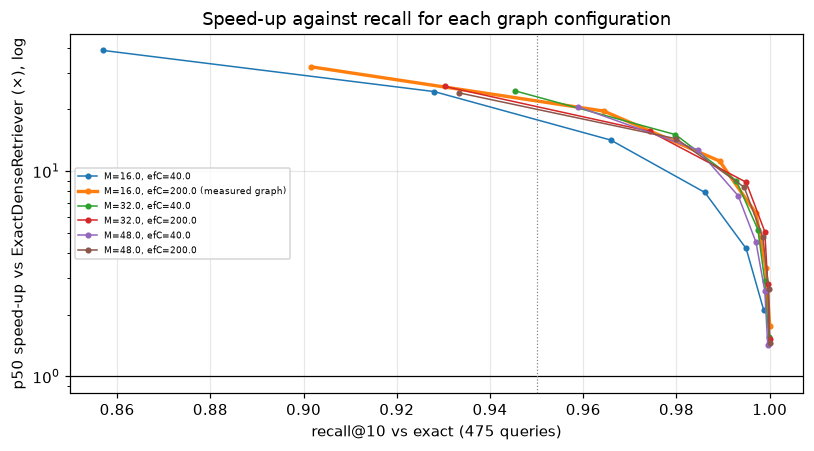

In [13]:
rb = latest_per_cell(load_step("robust"), ["index", "M", "efc", "ef", "round"], "robust")
rb = rb[rb["mode"] == "time"]
rp = load_step("robust-practice")
rp = rp[(rp["mode"] == "time") & (rp["run_ts"] == rp["run_ts"].max())]
RG = ["M", "efc", "ef"]
rc = (rb[rb["index"] == "hnsw"].groupby(RG).agg(recall=("recall_at_k", "median"), p50_us=("p50_us", "median"),
                                                lo=("p50_us", "min"), hi=("p50_us", "max"), ndis=("ndis_per_q", "median"),
                                                index_bytes=("index_bytes", "first"), n=("n", "first")).reset_index())
rc = rc.merge(rp[rp["index"] == "hnsw"].groupby(RG)["recall_at_k"].median().rename("practice_recall").reset_index(), on=RG)
dense_p50 = rb.loc[rb["index"] == "exact_dense", "p50_us"].median()
rc["speedup_vs_dense"] = dense_p50 / rc["p50_us"]
rc["extra_B_per_vec"] = rc["index_bytes"] / rc["n"] - 384 * 4
pick = (rc[rc["practice_recall"] >= 0.95].sort_values("ef").groupby(["M", "efc"]).head(1)
          .sort_values(["M", "efc"]).reset_index(drop=True))
display(Markdown(f"**Each configuration at its recall ≥ 0.95 point (chosen on practice queries)**; "
                 f"`ExactDenseRetriever` p50 in the same run = {dense_p50:,.0f} µs"))
display(pick[["M", "efc", "ef", "practice_recall", "recall", "ndis", "p50_us", "speedup_vs_dense", "extra_B_per_vec"]].round(3))
s = pick["speedup_vs_dense"]
print(f"speed-up at the >= 0.95 point across the grid: {s.min():.1f}x to {s.max():.1f}x "
      f"(default M=16, efc=200: {pick.set_index(['M', 'efc']).loc[(16, 200), 'speedup_vs_dense']:.1f}x)")

fig, ax = plt.subplots(figsize=(7.5, 4.2))
for (M_, efc_), g in rc.groupby(["M", "efc"]):
    g = g.sort_values("recall")
    ax.plot(g["recall"], g["speedup_vs_dense"], marker="o", ms=3, lw=2.2 if (M_, efc_) == (16, 200) else 1,
            label=f"M={M_}, efC={efc_}" + (" (measured graph)" if (M_, efc_) == (16, 200) else ""))
ax.axhline(1, c="k", lw=0.8); ax.axvline(0.95, c="grey", ls=":", lw=0.8)
ax.set(yscale="log", xlabel="recall@10 vs exact (475 queries)", ylabel="p50 speed-up vs ExactDenseRetriever (×), log",
       title="Speed-up against recall for each graph configuration")
ax.legend(fontsize=6)
fig.tight_layout(); savefig(fig, "orig_sq1_robustness")

### SQ1: answer as supported

**Claim.** At recall@10 ≈ 0.96 (ef = 32), single-threaded HNSW's p50 latency is **19.3× lower than `ExactDenseRetriever`** (2,167 → 112 µs). At recall ≈ 0.99 (ef = 64) it is **11.0× lower** (→ 197 µs).

**Where it comes from (§1b).** The speed-up is a large cut in work, partly given back as a higher cost per vector:
- **37× fewer vectors** at ef 32 (641 distance computations instead of 24,000), and 22.6× fewer at ef 64 (1,063).
- **Each vector costs 1.9–2.1× more** for HNSW than for the exact scan: 175–185 ns against 90 ns.
- **The extra cost per vector shows up as memory misses (`perf`).**
  - Exact search: 2.7 LLC misses per vector (out of 24 lines), ≈ 0 dTLB misses, 185 cycles.
  - HNSW at ef 32: 6.8 LLC misses per vector, 0.93 dTLB misses, 351 cycles.
  - The sequential scan has most of its lines fetched ahead by the prefetchers; HNSW's jumps get much less of that help.
  - As a rough cross-check: at the ≈28 cycles per avoided LLC miss measured in §2c, the 4.2 extra misses per vector would account for ~115 of the 167 extra cycles. The rest is graph bookkeeping (links, visited table, heap) and the dTLB misses. This split is approximate.

**The advantage shrinks steadily as ef rises.** The work saved falls faster than the per-vector cost:
- At ef 512 (recall ≈ 1.000), HNSW computes 4,796 distances, only 5× fewer than the full scan, at 261 ns per vector.
- Single-query HNSW is still faster at every ef measured, but only by 1.7× at ef 512.

**Robustness to the graph configuration (§1f).** Repeating the comparison on all six combinations of M ∈ {16, 32, 48} and efConstruction ∈ {40, 200}, each at its own recall ≥ 0.95 point chosen on practice queries, gives a speed-up of **14.2× to 20.5×** (recall 0.959–0.980). The fixed default gives 19.6× in that run, reproducing §1a (19.3×) to within 2%.
- The configuration moves the size of the speed-up by up to 30%, not its order of magnitude: no configuration falls below 14×.
- The fixed default is near the top of the range, but not at the top. M = 48, efConstruction = 40 reaches 0.95 already at ef 16 and gives 20.5×, so fixing the default did not pick the most favourable configuration.
- Part of the spread comes from the coarse ef grid: configurations whose ≥ 0.95 point lands at recall 0.97–0.98 pay for recall they weren't asked for.
- Larger M costs memory: +144, +272 and +400 B per vector for M = 16, 32 and 48.

**Evidence.** §1a table and figures: the speed-up curve, the same data as p50 latency against recall, and the batched curve. §1b decomposition and counters. §1e quality. §1f robustness table and figure.

**Alternatives ruled out**
- *"The speed-up is just a slow baseline."* No: the numpy baseline streams vectors at 17.0 GB/s. FAISS exact is only 8% faster, so the headline moves by under 10% whichever exact baseline is used: 17.7× against FAISS exact at ef 32.
- *"HNSW returns worse answers."* Barely: at ef = 32, recall@10, MRR@10 and nDCG@10 against the course qrels change by ≤ 0.01. At ef = 64, recall@10 falls by 0.003 and MRR@10 and nDCG@10 change by under 0.001.
- *"HNSW's per-step cost is negligible, so the speed-up equals the work saved."* No: the speed-up is about half the work reduction.
- *"The result depends on the chosen graph."* Only in size: 14–21× across the six configurations tested (§1f).

**Costs**
- **+144 B per vector (+9.4%)** of memory.
- **A one-off build of 12.2 s** on one P-core, with a max−min spread of 1.1% over 5 builds (≈509 µs per inserted vector). Two P-cores build it 2.0× faster.
  - Every build reproduces the saved graph exactly, so the search numbers apply to the graph whose build was timed.
- **Payback:** the build is repaid by the per-query saving after **≈5.9k queries** against `ExactDenseRetriever`, and ≈6.5k against FAISS exact.

**Limits**
- **Batching removes most of the advantage, and exact search wins at high recall.** The batched data was measured on 1 thread, with all queries in one call, against FAISS exact. `ExactDenseRetriever` has no batched call.
  - Batched FAISS exact takes ≈360 µs per query, against ≈2,000 µs single-query. It becomes a matrix multiply that loads each vector once for the whole batch.
  - HNSW's time per query barely changes (112 → 107 µs at ef 32), because each query walks its own path through the graph.
  - Batched HNSW still wins at ef 32 (3.4×) and ef 64 (1.9×), breaks even around ef 128 (1.06×), and is 3.5× *slower* at ef 512.
  - This does not affect the pipeline, which never batches (see scope above). It does limit the claim: HNSW's advantage depends on queries arriving one at a time.
- **One machine.** Every number is from one pinned P-core of one laptop CPU; how the speed-up transfers to other microarchitectures (cache sizes, prefetchers, memory bandwidth) is not measured.
- One corpus size (N = 24,000). How the speed-up changes with N isn't measured, so nothing here should be extrapolated to larger corpora.
- Graph configurations outside M ∈ {16, 32, 48} × efConstruction ∈ {40, 200} are not tested; the robustness check covers SQ1 only (SQ2 uses the fixed graph).
- AVX2 and single-threaded search only. The build was timed at 1 and 2 threads only.
- The exact scan's numpy array sits on 2 MiB transparent huge pages (numpy requests them with `madvise`), while FAISS's HNSW arrays are on 4 KiB pages. That flatters the exact scan's dTLB count; it doesn't change the LLC comparison.
- **None of this is user-visible in this pipeline.** Retrieval is 0.01% (HNSW) to 0.05% (exact) of the ~9.6–10 s end-to-end time (median, measured on the Xeon GPU node). The speed-up matters for retrieval-heavy workloads, not for this voice assistant as built.

## 2. SQ2: Does reordering the graph to improve memory locality cut latency further?

**What is reordered.** The saved HNSW graph and its vectors are relabelled (`permute_entries`) so that nodes which are linked sit at nearby positions in memory. The graph is the same, so each query visits the same nodes, computes the same distances and returns the same results. Only the memory layout changes.
- **BFS** orders nodes by breadth-first traversal from the entry point.
- **Gorder** greedily places together nodes that share many neighbours, within a window of w positions. w = 10 is fixed, not tuned; §2f shows the result does not depend on it.
- **Random** permutations (5 seeds) are the null hypothesis: same mechanics, no locality.

**Correctness check.** Before any timing, `bench.py` checks every reordered graph against the original order: the same top-k at every rank (or the same distance there, for exact ties) and the same number of distance computations. A mismatch aborts the run. So recall is identical by construction, and only latency is compared.

**Hypothesis.** The structured orderings cut p50 latency and the random ones don't. Gorder beats BFS. Each gain exceeds both the run-to-run noise and the spread across random layouts.

**Procedure and noise.** Same per-cell procedure as §1, over 5 interleaved rounds instead of 3. **Noise** is the larger of the ordering's own round-to-round spread and the original order's, as (max − min) ÷ median over the 5 rounds. A gain counts only if it exceeds both the noise and the largest random-seed gain.

In [14]:
RK = ["machine", "ef"]
per = (s4.groupby(RK + ["order"]).agg(p50=("p50_us", "median"), lo=("p50_us", "min"), hi=("p50_us", "max"),
                                      reorder_s=("reorder_s", "first")).reset_index())
per["family"] = per["order"].str.split(":").str[0]
base = per[per["order"] == "identity"].set_index(RK)
per = per.join(base[["p50", "lo", "hi"]].add_prefix("id_"), on=RK)
per["gain"] = 1 - per["p50"] / per["id_p50"]
per["round_spread"] = (per["hi"] - per["lo"]) / per["p50"]
rnd = per[per["family"] == "random"].groupby(RK)["gain"].agg(rand_min="min", rand_max="max", rand_mean="mean")
per = per.join(rnd, on=RK)
sel = per[(per["family"] == "bfs") | (per["order"] == GORDER)].copy()
sel["noise"] = np.maximum(sel["round_spread"], (sel["id_hi"] - sel["id_lo"]) / sel["id_p50"])
sel["beats_random"] = sel["gain"] > sel["rand_max"]
sel["beats_round_noise"] = sel["gain"] > sel["noise"]
display(sel[RK + ["order", "p50", "gain", "rand_min", "rand_max", "noise", "beats_random", "beats_round_noise"]]
          .sort_values(RK + ["order"]).reset_index(drop=True).round(4))

,machine,ef,order,p50,gain,rand_min,rand_max,noise,beats_random,beats_round_noise
0,Core Ultra 5 235U (12 MiB L3),32,bfs,107.5,0.0575,-0.0006,0.0059,0.0341,True,True
1,Core Ultra 5 235U (12 MiB L3),32,gorder:10,102.4,0.1017,-0.0006,0.0059,0.0107,True,True
2,Core Ultra 5 235U (12 MiB L3),64,bfs,186.5,0.0637,-0.002,0.0006,0.1714,True,False
3,Core Ultra 5 235U (12 MiB L3),64,gorder:10,177.5,0.1092,-0.002,0.0006,0.0083,True,True


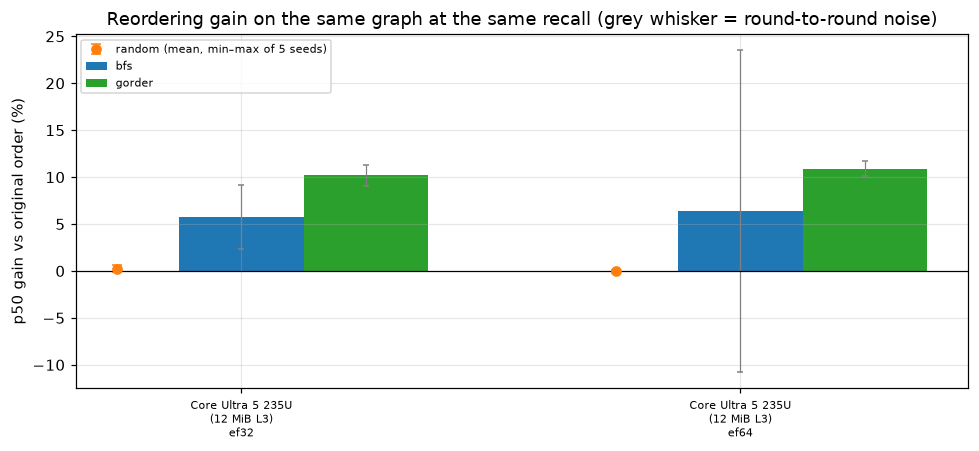

In [15]:
fig, ax = plt.subplots(figsize=(9, 4.2))
keys = sorted(sel.groupby(RK).groups)
x = np.arange(len(keys))
r = rnd.reindex(keys)
ax.errorbar(x - 0.25, 100 * r["rand_mean"], yerr=[100 * (r["rand_mean"] - r["rand_min"]), 100 * (r["rand_max"] - r["rand_mean"])],
            fmt="o", c=ORDER_COLORS["random"], capsize=3, label="random (mean, min–max of 5 seeds)")
for off, fam in [(0, "bfs"), (0.25, "gorder")]:
    s = sel[sel["family"] == fam].set_index(RK).reindex(keys)
    ax.bar(x + off, 100 * s["gain"], 0.25, color=ORDER_COLORS[fam], label=fam,
           yerr=100 * s["noise"], error_kw=dict(lw=0.8, capsize=2, ecolor="grey"))
ax.axhline(0, c="k", lw=0.8)
ax.set_xticks(x, [f"{tick(m)}\nef{ef:g}" for m, ef in keys], fontsize=7)
ax.set(ylabel="p50 gain vs original order (%)",
       title="Reordering gain on the same graph at the same recall (grey whisker = round-to-round noise)")
ax.legend(fontsize=7)
fig.tight_layout(); savefig(fig, "orig_c2_gain")

### 2b. Which property of an ordering predicts its gain?

The obvious locality metric is the mean ID gap across a link, and it ranks the orderings wrongly. The other statistics measure locality at scales the hardware uses:
- **Links within 64 IDs.** 64 vectors span ~96 KiB.
- **Adjacent siblings per neighbour.** Pairs of neighbours of one node that sit at consecutive positions. They are evaluated back to back.
- **Links sharing a 4 KiB page.**

The statistics come from the cached graph and permutations (`offline_locality.py`).

In [16]:
lc = loc.copy()
lc["family"] = lc["order"].str.split(":").str[0]
lc = lc[(lc["family"] != "gorder") | (lc["order"] == GORDER)]
lc = lc.groupby("family").mean(numeric_only=True)
gains = sel.pivot_table(index="family", columns="machine", values="gain", aggfunc="mean").add_prefix("gain: ")
show = ["mean_link_id_gap", "frac_links_within_64", "sibling_adjacent_pairs_per_neighbour", "frac_links_share_4k_page"]
display(lc[show].join(gains).reindex(["identity", "random", "bfs", "gorder"]).round(4))

,mean_link_id_gap,frac_links_within_64,sibling_adjacent_pairs_per_neighbour,frac_links_share_4k_page,gain: Core Ultra 5 235U (12 MiB L3)
family,,,,,
identity,7998,0.0053,0.0009,0.0002,NaN
random,8001,0.0052,0.0009,0.0002,NaN
bfs,5459,0.0247,0.0413,0.0024,0.0606
gorder,6804,0.1738,0.0651,0.0395,0.1054


### 2c. Why reordering helps: locality coarser than a cache line

**The argument**
- **Each vector spans 25 cache lines.** FAISS stores each vector as 1536 contiguous bytes, and the buffer starts at 16 mod 64 (measured: glibc's mmap header, unchanged by `permute_entries`). So each vector covers **25 cache lines**, one of them shared with the vector at the next position.
- **A permutation can save at most ~1 line in 25 (≈4%).** It moves whole vectors, so it doesn't change *which data* a query reads. It can change line misses in three small ways only:
  - a shared boundary line, when two neighbours are evaluated back to back;
  - the small link and visited-table lines;
  - set-associativity conflicts.
- **Real hardware also responds to locality coarser than a line:**
  - 4 KiB pages (2.67 vectors each), through the TLB;
  - the L2 spatial and stream prefetchers, which fetch lines ahead of demand once the next vector is nearby.

**What this section tests**
1. Do the hardware counters move far more than the ≈4% line-level ceiling allows? If they do, the gain cannot come from fewer distinct lines read (capacity), and must come from locality above the cache line.
2. Do the static statistics (sibling adjacency, page sharing) explain the counter changes directly?

Counters are `perf stat` user-space events on cpu 2, warm cache, switched on only around the timed passes (`perf stat -D -1 --control`), median over rounds.

In [17]:
hp = pt[pt["index"] == "hnsw"].copy()
hp["family"] = hp["order"].str.split(":").str[0]
hp = hp[(hp["family"] != "gorder") | (hp["order"] == GORDER)]
MET = ["cycles_per_q", "LLC_loads_per_q", "LLC_load_misses_per_q", "L1_dcache_load_misses_per_q", "dTLB_load_misses_per_q"]
pb = hp[hp["order"] == "identity"].set_index("ef")[MET]
fam = hp.groupby(["ef", "family"])[MET].mean()
ref = pb.reindex(fam.index.get_level_values("ef")).values
delta, pct = fam - ref, 100 * (fam - ref) / ref
out = pct.round(1).add_suffix(" Δ%")
out["cycles saved per LLC miss saved"] = (delta["cycles_per_q"] / delta["LLC_load_misses_per_q"]).where(lambda s: s > 0)
out["cycles saved per dTLB miss saved"] = (delta["cycles_per_q"] / delta["dTLB_load_misses_per_q"]).where(lambda s: s > 0)
out = out.drop(index="identity", level="family")
out.loc[out.index.get_level_values("family") == "random", ["cycles saved per LLC miss saved", "cycles saved per dTLB miss saved"]] = np.nan   # ratio of two ~0 deltas
display(Markdown(f"**Hardware counters per query on the {ULTRA}, change vs original order** (warm cache, `perf`)"))
display(out.round(1))

**Hardware counters per query on the Core Ultra 5 235U (12 MiB L3), change vs original order** (warm cache, `perf`)

cycles_per_q Δ%  LLC_loads_per_q Δ%  LLC_load_misses_per_q Δ%  L1_dcache_load_misses_per_q Δ%  dTLB_load_misses_per_q Δ%  cycles saved per LLC miss saved  cycles saved per dTLB miss saved
ef family                                                                                                                                                                                             
32 bfs                -5.2                -5.9                     -10.3                            -4.9                      -17.9                             25.7                             109.4
   gorder             -9.6               -11.8                     -17.8                            -8.8                      -32.8                             27.7                             110.9
   random              0.6                   0                       0.9                            -0.2                        0.6                              NaN                               NaN
64 bfs                -6.3                -7.4                     -11.4                            -5.5                      -19.9                             28.7                             118.4
   gorder            -10.7               -12.4                     -18.8                            -9.3                      -35.5                             29.3                             111.7
   random             -0.2                 0.2                       0.6                             0.3                        0.8                              NaN                               NaN

In [18]:
rows = []
for ef_ in sorted(sel["ef"].unique()):
    for f_ in ["random", "bfs", "gorder"]:
        o = out.loc[(ef_, f_)]
        lf = loc[(loc["order"] == GORDER) if f_ == "gorder" else loc["order"].str.startswith(f_)]
        w = sel if f_ != "random" else per
        w = w[(w["machine"] == ULTRA) & (w["ef"] == ef_) & (w["family"] == f_)]
        b = lf["sibling_adjacent_pairs_per_neighbour"].mean()
        rows.append({"ef": ef_, "family": f_,
                     "static_boundary_lines_per_ndis": b, "static_boundary_saving_%": 100 * b / 25,
                     "perf_LLC_miss_red_%": -o["LLC_load_misses_per_q Δ%"], "perf_LLC_loads_red_%": -o["LLC_loads_per_q Δ%"],
                     "perf_L1d_red_%": -o["L1_dcache_load_misses_per_q Δ%"], "perf_dTLB_red_%": -o["dTLB_load_misses_per_q Δ%"],
                     "perf_cycles_red_%": -o["cycles_per_q Δ%"], "wall_gain_%": 100 * w["gain"].mean()})
mech = pd.DataFrame(rows).set_index(["ef", "family"])
display(Markdown(f"**Line-level prediction vs measured reduction, per ordering** ({ULTRA}; line-level ceiling = 1 line in 25 = 4%)"))
display(mech.round(2))

**Line-level prediction vs measured reduction, per ordering** (Core Ultra 5 235U (12 MiB L3); line-level ceiling = 1 line in 25 = 4%)

static_boundary_lines_per_ndis  static_boundary_saving_%  perf_LLC_miss_red_%  perf_LLC_loads_red_%  perf_L1d_red_%  perf_dTLB_red_%  perf_cycles_red_%  wall_gain_%
ef family                                                                                                                                                                      
32 random                               0                         0                 -0.9                    -0             0.2             -0.6               -0.6         0.22
   bfs                               0.04                      0.17                 10.3                   5.9             4.9             17.9                5.2         5.75
   gorder                            0.07                      0.26                 17.8                  11.8             8.8             32.8                9.6        10.17
64 random                               0                         0                 -0.6                  -0.2            -0.3             -0.8                0.2        -0.04
   bfs                               0.04                      0.17                 11.4                   7.4             5.5             19.9                6.3         6.37
   gorder                            0.07                      0.26                 18.8                  12.4             9.3             35.5               10.7        10.92

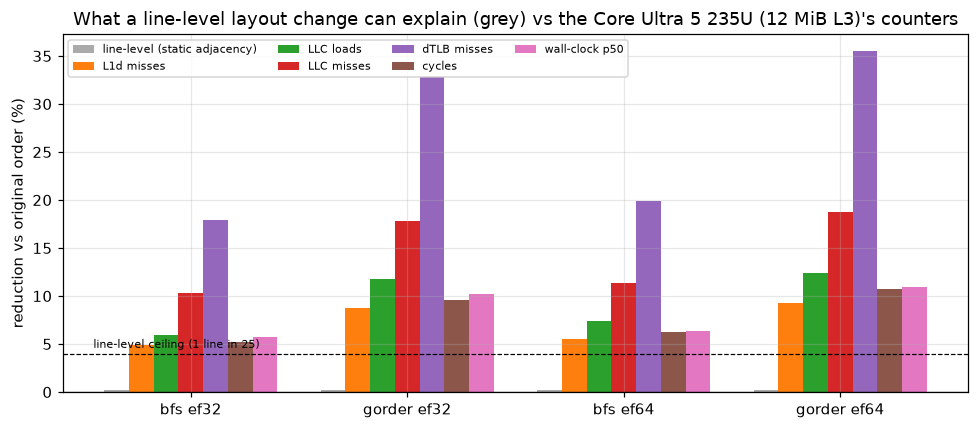

In [19]:
fig, ax = plt.subplots(figsize=(9, 4))
m = mech.drop(index="random", level="family")
cols_ = {"static_boundary_saving_%": "line-level (static adjacency)", "perf_L1d_red_%": "L1d misses",
         "perf_LLC_loads_red_%": "LLC loads", "perf_LLC_miss_red_%": "LLC misses", "perf_dTLB_red_%": "dTLB misses",
         "perf_cycles_red_%": "cycles", "wall_gain_%": "wall-clock p50"}
x = np.arange(len(m)); w = 0.8 / len(cols_)
for i, (k, lab) in enumerate(cols_.items()):
    ax.bar(x + (i - len(cols_) / 2 + 0.5) * w, m[k], w, label=lab, color="#aaaaaa" if i == 0 else f"C{i}")
ax.axhline(4, c="k", ls="--", lw=0.8); ax.annotate("line-level ceiling (1 line in 25)", (-0.45, 4.6), fontsize=7)
ax.set_xticks(x, [f"{f} ef{e:g}" for e, f in m.index])
ax.set(ylabel="reduction vs original order (%)",
       title=f"What a line-level layout change can explain (grey) vs the {ULTRA}'s counters")
ax.axhline(0, c="k", lw=0.8); ax.legend(fontsize=7, ncol=4)
fig.tight_layout(); savefig(fig, "orig_sq2_mechanism")

### 2d. Do neighbours simply share pages?

If page *sharing* between linked nodes drove the dTLB reduction, the fraction of links whose endpoints share a 4 KiB page would need to be of the same order as that reduction. The same holds for the fall in distinct pages touched per expansion.

In [20]:
pg = mech[["perf_dTLB_red_%"]].join(
    loc.assign(family=loc["order"].str.split(":").str[0])
       .loc[lambda d: (d["family"] != "gorder") | (d["order"] == GORDER)]
       .groupby("family")[["frac_links_share_4k_page", "distinct_4k_pages_per_neighbour"]].mean(),
    on="family")
pg["fewer_pages_per_expansion_%"] = 100 * (1 - pg["distinct_4k_pages_per_neighbour"])
display(pg.round(3))

perf_dTLB_red_%  frac_links_share_4k_page  distinct_4k_pages_per_neighbour  fewer_pages_per_expansion_%
ef family                                                                                                         
32 random             -0.6                         0                            0.999                        0.073
   bfs                17.9                     0.002                            0.972                        2.767
   gorder             32.8                     0.039                            0.951                        4.919
64 random             -0.8                         0                            0.999                        0.073
   bfs                19.9                     0.002                            0.972                        2.767
   gorder             35.5                     0.039                            0.951                        4.919

### 2e. What reordering costs

- **Reorder time:** computing each permutation from the loaded graph (including the level-0 CSR extraction), timed on the Core Ultra by `extensions/scripts/laptop_rerun.py reorder`: a fresh process per run, pinned to cpu 2, orderings interleaved over 5 shuffled rounds. The implementations are the pure-Python ones in `extensions/reorder.py`. Each recomputed permutation is checked against the cached one by hash.
- **Break-even:** median reorder time ÷ per-query p50 saving, both on the same pinned core.
- **`reorder_over_1t_build`:** reorder time relative to the single-thread graph build (§1d), on the same core.

In [21]:
rt_dir = run_dirs("reorder-time")[-1]
rt = pd.read_csv(rt_dir / "rows.csv")
print("source run:", rt_dir.name)
rts = rt.groupby("order")["reorder_s"].agg(runs="size", median="median", min="min", max="max")
rts["spread_%"] = 100 * (rts["max"] - rts["min"]) / rts["median"]
rts["same_perm_as_cached"] = rt.groupby("order")["same_as_cached"].all()
display(Markdown(f"**Reorder time on the {ULTRA}** (pinned cpu 2, fresh process per run, interleaved rounds)"))
display(rts.round(3))

be = sel.copy()
be["reorder_s"] = be["order"].map(rts["median"])
be["saving_us"] = be["id_p50"] - be["p50"]
be["breakeven_queries"] = be["reorder_s"] / (be["saving_us"] * 1e-6)
be["reorder_over_1t_build"] = be["reorder_s"] / one
display(be[RK + ["order", "reorder_s", "reorder_over_1t_build", "saving_us", "breakeven_queries"]]
          .sort_values(RK + ["order"]).reset_index(drop=True).round(3))

source run: jetsykes-hp-ubuntu-20261117T204523


**Reorder time on the Core Ultra 5 235U (12 MiB L3)** (pinned cpu 2, fresh process per run, interleaved rounds)

,runs,median,min,max,spread_%,same_perm_as_cached
order,,,,,,
bfs,5,0.045,0.043,0.045,3.046,True
gorder:10,5,81.2,80.76,81.48,0.886,True
random:0,5,0.001,0.001,0.001,2.531,True


,machine,ef,order,reorder_s,reorder_over_1t_build,saving_us,breakeven_queries
0,Core Ultra 5 235U (12 MiB L3),32,bfs,0.045,0.004,6.558,6799
1,Core Ultra 5 235U (12 MiB L3),32,gorder:10,81.2,6.651,11.6,7.001e+06
2,Core Ultra 5 235U (12 MiB L3),64,bfs,0.045,0.004,12.69,3513
3,Core Ultra 5 235U (12 MiB L3),64,gorder:10,81.2,6.651,21.75,3.734e+06


### 2f. Does the choice of Gorder's window matter?

w = 10 is fixed, not tuned (the Gorder reference implementation defaults to w = 5). This check times Gorder with w = 3 and 5 against w = 10 on the same graph, at the same ef values, pinned on the Core Ultra over 5 interleaved rounds (`extensions/scripts/retune.py`). It uses the 350 practice queries, so its gains are close to, but not identical with, the §2a table (475 queries). A difference counts only if it exceeds the round-to-round noise of both windows.

In [22]:
rt_runs = sorted((HERE / "laptop" / "ann" / "retune").glob("*/rows-gorder.csv"))
if not rt_runs:
    print("no retune run yet: run extensions/scripts/retune.py (see its docstring)")
else:
    f = rt_runs[-1]
    print("source run:", f.parent.name)
    rg = pd.read_csv(f)
    rg = rg[rg["mode"] == "time"]
    t = rg.groupby(["ef", "order"])["p50_us"].agg(p50="median", lo="min", hi="max").reset_index()
    idn = t[t["order"] == "identity"].set_index("ef")
    t = t[t["order"] != "identity"].join(idn[["p50", "lo", "hi"]].add_prefix("id_"), on="ef")
    t["w"] = t["order"].str.split(":").str[1].astype(int)
    t["gain"] = 1 - t["p50"] / t["id_p50"]
    t["noise"] = np.maximum((t["hi"] - t["lo"]) / t["p50"], (t["id_hi"] - t["id_lo"]) / t["id_p50"])
    W = int(settings[CORPUS]["gorder_w"])
    ref = t[t["w"] == W].set_index("ef")
    t["gain_vs_fixed_w"] = t["gain"] - t["ef"].map(ref["gain"])
    t["differs_from_fixed_w"] = t["gain_vs_fixed_w"].abs() > np.maximum(t["noise"], t["ef"].map(ref["noise"]))
    display(Markdown(f"**Gorder gain by window on the {ULTRA}** (350 practice queries; fixed w = {W})"))
    display(t[["ef", "w", "p50", "gain", "noise", "gain_vs_fixed_w", "differs_from_fixed_w"]]
              .sort_values(["ef", "w"]).reset_index(drop=True).round(4))

source run: jetsykes-hp-ubuntu-20261117T211256


**Gorder gain by window on the Core Ultra 5 235U (12 MiB L3)** (350 practice queries; fixed w = 10)

,ef,w,p50,gain,noise,gain_vs_fixed_w,differs_from_fixed_w
0,32,3,102,0.1057,0.0256,-0.0041,False
1,32,5,102.2,0.1042,0.0256,-0.0056,False
2,32,10,101.5,0.1098,0.0256,0,False
3,64,3,178.1,0.1088,0.0411,-0.0025,False
4,64,5,177.2,0.1133,0.0178,0.002,False
5,64,10,177.6,0.1113,0.0178,0,False


### SQ2: answer as supported

**Claim.** Relabelling the saved graph changes no result and no distance computation. Even so, it cuts single-query p50 latency:

| | ef 32 | ef 64 |
|---|---|---|
| **Gorder** (w = 10) | **10.2%** | **10.9%** |
| **BFS** | 5.8% | 6.4% |
| **Random** (5 seeds) | −0.1 to +0.6% | −0.2 to +0.1% |

The original order behaves exactly like a random layout: the same mean link-ID gap (≈8,000) and the same fraction of short links (0.5%). So the original ID order carries no locality.

**Reliability**
- **Gorder** exceeds both the random-seed spread and the round-to-round noise at both ef values (noise 1.1% and 0.8%).
- **BFS** exceeds the random-seed spread at both ef values, and the noise at ef 32 (5.8% against 3.4%).
- **BFS at ef 64 fails the noise test, because of one round.** Its round 0 measured 217.8 µs; the other four rounds lie within 185.8–186.9 µs (0.6%). The max−min noise measure is therefore 17%. The median, and so the 6.4% gain, is unaffected, and the gain is still far above the largest random-seed gain (0.06%). BFS's ef 32 high value is also in round 0. The rule was not relaxed after the fact: this cell is reported as not clearing the noise test, with the outlier shown.
- Gorder's gain is 1.7–1.8× BFS's at both ef values.

**What predicts the gain: short-range locality, not the average gap (§2b).** The mean link-ID gap gets the ranking wrong: BFS has the *smallest* gap (5,459 vs Gorder's 6,804) but the smaller gain. What tracks the gain is how many links stay very close in memory:

| | Original / random | BFS | Gorder |
|---|---|---|---|
| Mean link-ID gap | ≈8,000 | 5,459 | 6,804 |
| Links within 64 IDs | 0.5% | 2.5% | 17.4% |
| Adjacent siblings per neighbour | 0.0009 | 0.041 | 0.065 |
| Gain (mean of ef 32 and 64) | ≈0 | 6.1% | 10.5% |

**Mechanism: locality coarser than a cache line (§2c, §2d).** Reordering speeds up HNSW through hardware prefetching and/or fewer TLB misses once linked vectors sit close together, not by reducing the number of lines read.
- **A permutation can save at most ≈4% of line misses** (1 line in 25), and the static sibling adjacency predicts much less: 0.04 (BFS) and 0.07 (Gorder) boundary lines per distance computation, i.e. 0.2–0.3%.
- **The counters move far beyond that:**

  | Change vs original order | Gorder | BFS | Random |
  |---|---|---|---|
  | LLC load misses | −17.8 to −18.8% | −10.3 to −11.4% | within ±0.9% |
  | LLC loads | −11.8 to −12.4% | −5.9 to −7.4% | within ±0.2% |
  | L1d misses | −8.8 to −9.3% | −4.9 to −5.5% | within ±0.3% |
  | dTLB misses | −32.8 to −35.5% | −17.9 to −19.9% | within ±0.8% |
  | cycles | −9.6 to −10.7% | −5.2 to −6.3% | within ±0.6% |

  - A layout change that saves at most 1 line in 25 can't cut LLC misses by 18–19%. So the reduction must come from mechanisms that act above the line: the prefetchers and the TLB.
  - LLC *loads* fall as well: requests are being satisfied before they reach the LLC, which is what an L2 prefetcher does.
- **The cost per avoided miss is low and steady.** Every structured cell saves **≈28 cycles per avoided LLC miss** (25.7–29.3), far below a DRAM round trip. So most of the avoided misses were already overlapping with other work, and miss counts alone overstate the time saved by roughly an order of magnitude.

**Alternatives ruled out**
- *"Reordering helps by reducing LLC capacity pressure."* A permutation moves whole vectors, so the set of lines a query reads changes by at most ≈4%; an 18–19% fall in LLC misses can't come from fewer distinct lines. (This is argued from the byte layout, not simulated.)
- *"Linked nodes simply share pages."* Only 3.9% of Gorder's links share a 4 KiB page, and an expansion touches only 4.9% fewer distinct pages (§2d). Neither comes close to a 33–36% dTLB fall. If the TLB effect is real, it comes from reuse *across hops* of a query: Gorder keeps a query's neighbourhood within a window of ~64 IDs, about 24 pages.
- *"Line-level adjacency explains it."* Static sibling adjacency ranks the orderings correctly but predicts 0.2–0.3%, against a 10–19% fall in LLC misses.

**Not resolved: how the ~10% splits between prefetching and the TLB**
- The LLC and dTLB reductions move together in every cell, so they're collinear.
- Each alone could account for the cycles saved: ≈28 cycles per avoided LLC miss, or ≈109–118 per avoided dTLB miss (about one page walk).
- The discriminating run is the `perf` step with transparent huge pages forced on (2 MiB pages, ~1,365 vectors each): if TLB reach is the mechanism, Gorder's gain should fall well below 10%; if it stays near 10%, the mechanism is the prefetchers.
- Until that run is done, state the mechanism as "locality above the cache line, via prefetching and/or the TLB".

**Does the gain grow as the working set outgrows the cache?** The project brief predicted it would. This machine gives one ratio (ws ≈ 3× L3) and there is one corpus size, so the prediction is **untested**, not refuted.

**Cost (§2e)**
- **BFS** takes 0.045 s on the pinned P-core and pays back after **3.5k–6.8k queries**.
- **Pure-Python Gorder** takes 81 s, which is ≈6.7× the single-thread graph build. It pays back after **3.7M–7.0M queries**, for 1.7–1.8× BFS's gain.
- At this pipeline's query volumes only BFS pays back. The Gorder figure is the cost of a Python port; a compiled implementation would be much cheaper.

**Limits**
- One machine, one corpus, one graph configuration (M = 16, efConstruction = 200, the common hnswlib defaults, fixed rather than tuned), one query set.
- **Gorder's w was fixed at 10, not tuned.** §2f shows the choice does not matter here: w = 3 and w = 5 (the reference implementation's default) give gains within 0.6 points of w = 10 at both ef values, inside the round-to-round noise (1.8–4.1%).
- Counters were taken with a warm cache; Intel's `LLC-load-misses` counts demand loads only; hardware prefetchers were not switched off (MSR writes weren't attempted).

## 3. Synthesis

The two answers tell one story about where the time goes in graph-based retrieval:

1. **HNSW wins by doing far less work (SQ1).** It evaluates ~640 (ef 32) to ~1,060 (ef 64) vectors per query instead of all 24,000, which gives a 19.3× single-query speed-up at recall ≈ 0.96 (11.0× at 0.99), for +9.4% memory and a 12.2 s build that pays back after ≈5.9k queries. Across six graph configurations the speed-up at recall ≥ 0.95 stays within 14–21×.
2. **What is left of HNSW's cost is memory access (SQ1 → SQ2).** Each vector HNSW evaluates costs about twice what a vector costs in the sequential scan, and the difference tracks LLC misses: the graph walk's jumps defeat the prefetching a scan gets. That makes memory layout the natural next lever.
3. **Layout recovers a reliable ~10% (SQ2).** Relabelling the graph so linked nodes sit close together cuts p50 by 10.2–10.9% (Gorder) without changing a single result. The gain follows short-range locality (links within ~64 IDs), not the average gap.
4. **The gain comes from hardware above the cache line (SQ2).** LLC misses fall 2.6–4.7× and dTLB misses 4.5–9× more than the ≈4% any line-level effect allows, so the effect works through prefetching and the TLB. It follows that layouts should be evaluated on hardware, with counters, not in a line-level cache simulator, which has neither.

**What the evidence does not support**
- That any of this is user-visible in this pipeline: retrieval is < 0.1% of end-to-end time.
- Anything about other machines or larger corpora: one CPU and one corpus size were measured.
- That SQ2's gain holds on other graph configurations: the robustness check covers SQ1 only.
- Which of prefetching or the TLB drives SQ2's gain. The THP run would settle it.